# Classification and Prediction

## Imports

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict
from sklearn.metrics import balanced_accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

RANDOM_STATE = 0

## Paths and loading

In [2]:
project_dir = Path.cwd().parent
data_filepath = project_dir / "processed_data" / "pseudobulked_by_celltype_Epi_filtered.h5ad"

results_dir = Path.cwd() / "results"
results_dir.mkdir(exist_ok=True)

pb = sc.read_h5ad(data_filepath)
pb

AnnData object with n_obs × n_vars = 292 × 2000
    obs: 'samples', 'cell_type_group', 'Subject', 'Health', 'psbulk_cells', 'psbulk_counts'
    var: 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection', 'mean', 'std'
    layers: 'psbulk_props', None (.X)

In [3]:
c = pb.X.toarray() if hasattr(pb.X, "toarray") else pb.X
print(c.min(), np.allclose(c, np.round(c)))

0.0 True


## Look at the data

In [4]:
print(pb.obs.columns.tolist())
pd.crosstab(pb.obs["cell_type_group"], pb.obs["Health"], margins=True)

['samples', 'cell_type_group', 'Subject', 'Health', 'psbulk_cells', 'psbulk_counts']


Health,Healthy,Inflamed,Non-inflamed,All
cell_type_group,,,,
Enterocytes,27,24,29,80
Goblet,22,20,26,68
M cells,0,2,0,2
Stem,11,6,9,26
Transit Amplifying,38,36,41,115
Tuft,0,1,0,1
All,98,89,105,292


## Labels and patient groups

In [5]:
LABEL_COL = "Health"
CELLTYPE_COL = "cell_type_group"

if "Subject" in pb.obs.columns:
    GROUP_COL = "Subject"
else:
    GROUP_COL = "samples"
    print("WARNING: no 'Subject' column, grouping by 'samples'.")

print("Grouping CV by:", GROUP_COL)
print("Patients:", pb.obs[GROUP_COL].nunique())

Grouping CV by: Subject
Patients: 30


## Normalize

In [6]:
pb.layers["counts"] = pb.X.copy()
sc.pp.normalize_total(pb, target_sum=1e6)
sc.pp.log1p(pb)

## Classifier per cell type

In [7]:
# skip cell types with fewer samples than this
MIN_SAMPLES = 15
# gene must be detected in this fraction of samples
MIN_DETECT_FRAC = 0.2 
N_SPLITS = 5
# smaller = stronger regularization
C = 0.1

def make_model():
    return make_pipeline(
        StandardScaler(),
        LogisticRegression(C=C, max_iter=5000, random_state=RANDOM_STATE),
    )

def subset_celltype(adata, ct):
    sub = adata[adata.obs[CELLTYPE_COL] == ct]
    counts = sub.layers["counts"]
    counts = counts.toarray() if hasattr(counts, "toarray") else np.asarray(counts)
    keep = (counts > 0).mean(axis=0) >= MIN_DETECT_FRAC
    X = sub.X.toarray() if hasattr(sub.X, "toarray") else np.asarray(sub.X)
    return X[:, keep], sub.var_names[keep], sub.obs[LABEL_COL].astype(str).values, sub.obs[GROUP_COL].astype(str).values

def run_celltype(ct):
    X, genes, y, groups = subset_celltype(pb, ct)
    n_splits = min(N_SPLITS, len(np.unique(groups)))
    cv = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_STATE)
    y_pred = cross_val_predict(make_model(), X, y, groups=groups, cv=cv)
    return {
        "cell_type": ct,
        "n_samples": len(y),
        "n_genes": X.shape[1],
        "balanced_acc": balanced_accuracy_score(y, y_pred),
        "macro_f1": f1_score(y, y_pred, average="macro"),
    }, (X, genes, y, y_pred)

In [8]:
counts_per_ct = pb.obs[CELLTYPE_COL].value_counts()
cell_types = counts_per_ct[counts_per_ct >= MIN_SAMPLES].index.tolist()
print("Running on:", cell_types)
print("Skipped (too few samples):", counts_per_ct[counts_per_ct < MIN_SAMPLES].index.tolist())

results, details = [], {}
for ct in cell_types:
    res, det = run_celltype(ct)
    results.append(res)
    details[ct] = det

results_df = pd.DataFrame(results).sort_values("balanced_acc", ascending=False)
results_df.to_csv(results_dir / "celltype_cv_scores.csv", index=False)
results_df  # chance level for 3 balanced classes is about 0.33

Running on: ['Transit Amplifying', 'Enterocytes', 'Goblet', 'Stem']
Skipped (too few samples): ['M cells', 'Tuft']


,cell_type,n_samples,n_genes,balanced_acc,macro_f1
2,Goblet,68,1889,0.691492,0.685126
3,Stem,26,1853,0.648148,0.624396
1,Enterocytes,80,1950,0.640166,0.629860
0,Transit Amplifying,115,1993,0.556364,0.556150


## Confusion matrices

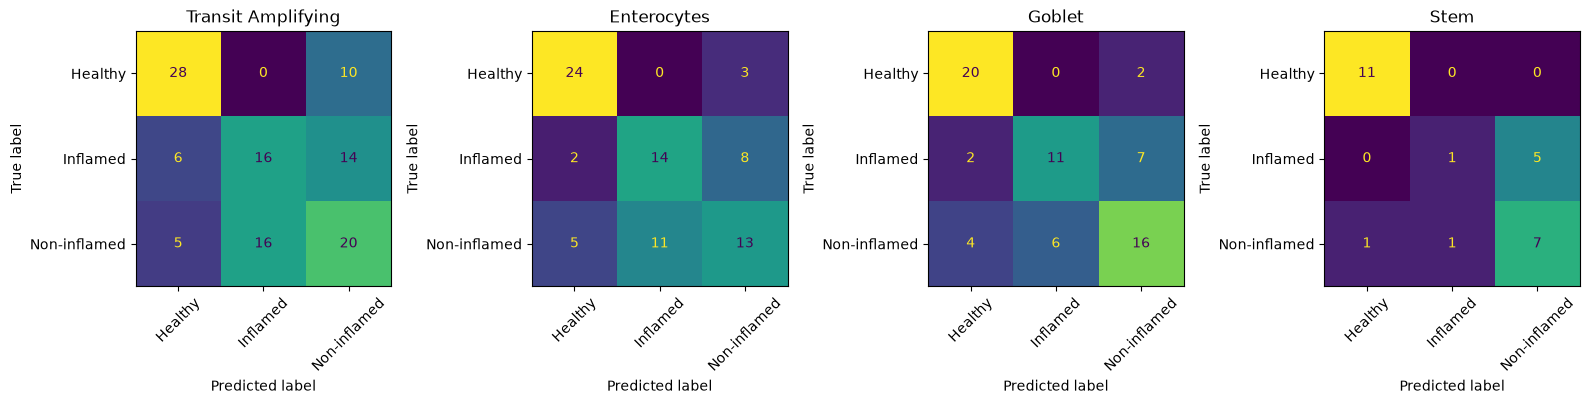

In [9]:
n = len(details)
fig, axes = plt.subplots(1, n, figsize=(4 * n, 4), squeeze=False)
for ax, (ct, (_, _, y, y_pred)) in zip(axes[0], details.items()):
    ConfusionMatrixDisplay.from_predictions(y, y_pred, ax=ax, colorbar=False, xticks_rotation=45)
    ax.set_title(ct)
plt.tight_layout()
plt.show()

## Model comparison (logistic regression, random forest, SVM)


In [10]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import roc_auc_score

MODELS = {
    "logreg": lambda: make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=5000, random_state=RANDOM_STATE)),
    "random_forest": lambda: RandomForestClassifier(n_estimators=500, random_state=RANDOM_STATE, n_jobs=-1),
    "linear_svm": lambda: make_pipeline(StandardScaler(), SVC(kernel="linear", C=C, probability=True, random_state=RANDOM_STATE)),
}

def score_model(name, ct):
    X, genes, y, groups = subset_celltype(pb, ct)
    cv = StratifiedGroupKFold(n_splits=min(N_SPLITS, len(np.unique(groups))), shuffle=True, random_state=RANDOM_STATE)
    proba = cross_val_predict(MODELS[name](), X, y, groups=groups, cv=cv, method="predict_proba")
    classes = np.unique(y)
    y_pred = classes[proba.argmax(axis=1)]
    return {
        "cell_type": ct, "model": name, "n_samples": len(y),
        "balanced_acc": balanced_accuracy_score(y, y_pred),
        "macro_f1": f1_score(y, y_pred, average="macro"),
        "roc_auc": roc_auc_score(y, proba, multi_class="ovr", labels=classes),
    }


In [11]:
model_scores = pd.DataFrame([score_model(m, ct) for ct in cell_types for m in MODELS])
model_scores.to_csv(results_dir / "celltype_cv_scores_by_model.csv", index=False)
model_scores.pivot(index="cell_type", columns="model", values="balanced_acc")


/Users/kingjulien/venvs/uc/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Users/kingjulien/venvs/uc/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Users/kingjulien/venvs/uc/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Users/kingjulien/venvs/uc/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was depreca

model,linear_svm,logreg,random_forest
cell_type,,,
Enterocytes,0.543636,0.640166,0.659217
Goblet,0.663287,0.691492,0.582517
Stem,0.611111,0.648148,0.685185
Transit Amplifying,0.518198,0.556364,0.581550


In [12]:
rows = []
TOP_N = 20

for ct in cell_types:
    X, genes, y, _ = subset_celltype(pb, ct)
    for name in MODELS:
        m = MODELS[name]().fit(X, y)
        est = m[-1] if hasattr(m, "steps") else m
        if name == "random_forest":
            imp = est.feature_importances_
        else:
            imp = np.abs(est.coef_).max(axis=0)
        for rank, i in enumerate(np.argsort(-imp)[:TOP_N], 1):
            rows.append({"cell_type": ct, "model": name, "rank": rank, "gene": genes[i], "importance": imp[i]})

top_by_model = pd.DataFrame(rows)
top_by_model.to_csv(results_dir / "celltype_top_genes_by_model.csv", index=False)
top_by_model.groupby(["cell_type", "gene"]).model.nunique().loc[lambda s: s == 3]

/Users/kingjulien/venvs/uc/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Users/kingjulien/venvs/uc/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Users/kingjulien/venvs/uc/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Users/kingjulien/venvs/uc/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was depreca

cell_type    gene    
Enterocytes  C12orf75    3
             S100P       3
Goblet       ITM2A       3
Name: model, dtype: int64

## Top genes per cell type

In [13]:
top_rows = []
for ct, (X, genes, y, _) in details.items():
    model = make_model().fit(X, y)
    lr = model[-1]
    for cls, coefs in zip(lr.classes_, lr.coef_):
        order = np.argsort(-np.abs(coefs))[:TOP_N]
        for rank, i in enumerate(order, 1):
            top_rows.append({"cell_type": ct, "class": cls, "rank": rank, "gene": genes[i], "coef": coefs[i]})

top_genes = pd.DataFrame(top_rows)
top_genes.to_csv(results_dir / "celltype_top_genes.csv", index=False)
top_genes.head(20)

,cell_type,class,rank,gene,coef
0,Transit Amplifying,Healthy,1,S100P,-0.054500
1,Transit Amplifying,Healthy,2,MUC12,-0.045634
2,Transit Amplifying,Healthy,3,PLA2G2A,-0.043381
3,Transit Amplifying,Healthy,4,SOD3,-0.042656
4,Transit Amplifying,Healthy,5,RP11-338I21.1,-0.042469
5,Transit Amplifying,Healthy,6,APOD,-0.038918
6,Transit Amplifying,Healthy,7,ST3GAL4,-0.038558
7,Transit Amplifying,Healthy,8,TFF1,-0.037462
8,Transit Amplifying,Healthy,9,ETNK1,0.037014
9,Transit Amplifying,Healthy,10,TMEM200A,-0.036386


## By Cluster

In [14]:
cl_path = project_dir / "processed_data" / "pseudobulked_by_cluster_Epi_filtered.h5ad"
pb_cl = sc.read_h5ad(cl_path)
pb_cl.layers["counts"] = pb_cl.X.copy()
sc.pp.normalize_total(pb_cl, target_sum=1e6)
sc.pp.log1p(pb_cl)
pd.crosstab(pb_cl.obs["leiden"], pb_cl.obs["Health"], margins=True)

Health,Healthy,Inflamed,Non-inflamed,All
leiden,,,,
0,23,12,21,56
1,26,20,21,67
2,25,23,31,79
3,27,26,32,85
4,33,26,34,93
5,0,0,1,1
6,5,8,11,24
7,1,1,1,3
8,14,5,8,27


In [15]:
pb_ct, ct_col = pb, CELLTYPE_COL
pb, CELLTYPE_COL = pb_cl, "leiden"

n_per = pb.obs[CELLTYPE_COL].value_counts()
n_states = pb.obs.groupby(CELLTYPE_COL, observed=True)[LABEL_COL].nunique()
clusters = [c for c in n_per.index if n_per[c] >= MIN_SAMPLES and n_states[c] == 3]
print("Running on clusters:", clusters)

cl_scores = pd.DataFrame([score_model(m, c) for c in clusters for m in MODELS])

pb, CELLTYPE_COL = pb_ct, ct_col

cl_scores.to_csv(results_dir / "cluster_cv_scores_by_model.csv", index=False)
cl_scores.pivot(index="cell_type", columns="model", values="balanced_acc")

Running on clusters: ['4', '3', '2', '1', '0', '8', '6']


/Users/kingjulien/venvs/uc/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Users/kingjulien/venvs/uc/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Users/kingjulien/venvs/uc/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Users/kingjulien/venvs/uc/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was depreca

model,linear_svm,logreg,random_forest
cell_type,,,
0,0.586094,0.624396,0.658730
1,0.605189,0.605983,0.647497
2,0.652155,0.541786,0.608677
3,0.624347,0.635387,0.602060
4,0.507564,0.540747,0.500914
6,0.453788,0.500758,0.290152
8,0.519048,0.434524,0.434524
